# Bank Marketing | Model optimization lab

**Goal:** improve the `yes` class F1-score while checking precision, recall and average precision.

- Keep `poutcome` as an encoded category; keep `contact=unknown` as a category.
- Replace `job` / `education` `unknown` with training-fold mode inside a Pipeline.
- Exclude `duration` because it is not available before a marketing call ends.
- Compare **current balanced RandomForest**, **RandomizedSearchCV RandomForest**, and **HistGradientBoosting**.
- Tune the **decision threshold** only on validation data and evaluate the selected model **once on held-out test data**.

The previously saved notebook reported accuracy **0.8792**, `yes` recall **0.399**, and `yes` F1 **0.43**. This notebook uses a different data split, so do not compare the new test scores to those numbers directly.

**Data availability:** The original CSV is not included in this notebook. Place `bank-full.csv` next to this notebook or run with Internet access so the original URL can be read. `input_bank_submission.csv` is optional.


## 1. Load data

In [1]:
from pathlib import Path
from io import StringIO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_URL = "https://raw.githubusercontent.com/suyongzz/AICampus/refs/heads/main/bank-full.csv"
DATA_LOCAL = Path("bank-full.csv")
source = str(DATA_LOCAL) if DATA_LOCAL.exists() else DATA_URL

bank_full = pd.read_csv(source, sep=";", quotechar='"')
# Compatibility with the wrapped CSV format used in the original notebook.
if bank_full.shape[1] == 1:
    wrapped = pd.read_csv(source)
    text = "\n".join([wrapped.columns[0]] + wrapped.iloc[:, 0].astype(str).tolist())
    bank_full = pd.read_csv(StringIO(text), sep=";", quotechar='"')

assert bank_full.shape[1] == 17 and 'y' in bank_full.columns
print("Rows, columns:", bank_full.shape)
print("Target distribution:")
print(bank_full['y'].value_counts(normalize=True).round(3))
display(bank_full.head())

Rows, columns: (45111, 17)
Target distribution:
y
no     0.884
yes    0.116
Name: proportion, dtype: float64


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 2. Feature engineering and three-way split

An additional `PrevContacted` flag may capture a distinct split in the trees, but its information overlaps with `previous`. `poutcome_success` is already represented by One-Hot Encoding, so there is **no need to add a duplicate success column**.

In [ ]:
from sklearn.model_selection import train_test_split

def make_features(df):
    out = df.copy()
    out['PrevContacted'] = (out['previous'] > 0).astype(int)
    out['NeverContactedPdays'] = (out['pdays'] == -1).astype(int)
    return out

raw_X = bank_full.drop(columns=['y', 'duration'])
X = make_features(raw_X)
y = bank_full['y'].astype(str)
assert set(y.unique()).issubset({'yes', 'no'})

# 60% train / 20% validation / 20% test
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.3, random_state=2026, stratify=y
)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=2026, stratify=y_dev
)
print('Train:', X_train.shape, 'Validation:', X_valid.shape, 'Test:', X_test.shape)

Train: (27066, 17) Validation: (9022, 17) Test: (9023, 17)


## 3. Preprocessing without leakage

Fit the imputation and One-Hot Encoding *inside* the Pipeline. This is important for cross-validation and ensures identical transformations for the final submission data.

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

mode_cols = ['job', 'education']
numeric_cols = X.select_dtypes(include='number').columns.tolist()
other_categorical_cols = [
    c for c in X.select_dtypes(exclude='number').columns
    if c not in mode_cols
]

preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', SimpleImputer(strategy='median'), numeric_cols),
        ('mode_categories', Pipeline([
            ('imputer', SimpleImputer(missing_values='unknown', strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), mode_cols),
        ('other_categories', OneHotEncoder(handle_unknown='ignore', sparse_output=False),
         other_categorical_cols),
    ],
    sparse_threshold=0
)
print('Numeric:', numeric_cols)
print('Mode-imputed categorical:', mode_cols)
print('Other categorical:', other_categorical_cols)

Numeric: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous', 'PrevContacted', 'NeverContactedPdays']
Mode-imputed categorical: ['job', 'education']
Other categorical: ['marital', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


## 4. Baseline + randomized search + boosting

`RandomizedSearchCV` selects parameters using **F1 for the yes class**, with stratified 3-fold CV. Do not change models after inspecting the test result. The search can require noticeable CPU time; reduce `n_iter=12` to `n_iter=6` for a quicker learning run.

In [4]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import make_scorer, f1_score

scorer = make_scorer(f1_score, pos_label='yes')
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

baseline_rf = Pipeline([
    ('preprocess', clone(preprocessor)),
    ('model', RandomForestClassifier(
        class_weight='balanced', min_samples_leaf=2,
        random_state=42, n_jobs=-1
    ))
])
baseline_rf.fit(X_train, y_train)

search_pipe = Pipeline([
    ('preprocess', clone(preprocessor)),
    ('model', RandomForestClassifier(random_state=42, n_jobs=1))
])
search_space = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [None, 12, 20],
    'model__min_samples_leaf': [1, 2, 4, 8],
    'model__min_samples_split': [2, 5, 10],
    'model__max_features': ['sqrt', 0.7],
    'model__class_weight': [None, 'balanced', 'balanced_subsample'],
}

rf_search = RandomizedSearchCV(
    search_pipe, search_space,
    n_iter=12, scoring=scorer, cv=cv,
    random_state=42, n_jobs=-1, refit=True, verbose=1,
    error_score='raise'
)
rf_search.fit(X_train, y_train)
print('Best cross-validation yes F1:', round(rf_search.best_score_, 4))
print('Best RandomForest parameters:', rf_search.best_params_)

boosting = Pipeline([
    ('preprocess', clone(preprocessor)),
    ('model', HistGradientBoostingClassifier(
        learning_rate=0.05, max_iter=200, max_leaf_nodes=20,
        l2_regularization=1.0, class_weight='balanced',
        early_stopping=True, random_state=42
    ))
])
boosting.fit(X_train, y_train)

candidates = {
    'RF existing balanced': baseline_rf,
    'RF tuned': rf_search.best_estimator_,
    'HistGradientBoosting': boosting
}

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best cross-validation yes F1: 0.4602
Best RandomForest parameters: {'model__n_estimators': 300, 'model__min_samples_split': 2, 'model__min_samples_leaf': 8, 'model__max_features': 'sqrt', 'model__max_depth': 20, 'model__class_weight': 'balanced_subsample'}


## 5. Optimize threshold on validation only

The standard cutoff `0.5` is not automatically optimal for F1. Lower values often increase recall but may reduce precision. The table and chart make this tradeoff visible.

In [5]:
from sklearn.metrics import (
    precision_score, recall_score, f1_score, average_precision_score
)

threshold_grid = np.round(np.arange(0.10, 0.801, 0.025), 3)
records = []
prob_by_model = {}

for name, estimator in candidates.items():
    yes_idx = list(estimator.classes_).index('yes')
    probs = estimator.predict_proba(X_valid)[:, yes_idx]
    prob_by_model[name] = probs
    ap = average_precision_score((y_valid == 'yes').astype(int), probs)
    for threshold in threshold_grid:
        pred = np.where(probs >= threshold, 'yes', 'no')
        records.append({
            'model': name,
            'threshold': threshold,
            'precision': precision_score(y_valid, pred, pos_label='yes', zero_division=0),
            'recall': recall_score(y_valid, pred, pos_label='yes', zero_division=0),
            'f1': f1_score(y_valid, pred, pos_label='yes', zero_division=0),
            'average_precision': ap
        })

validation_results = pd.DataFrame(records)
summary = (validation_results.sort_values(['f1', 'precision'], ascending=False)
           .groupby('model', as_index=False).first()
           .sort_values('f1', ascending=False))
display(summary.round(3))

chosen = summary.iloc[0]
best_name = chosen['model']
best_threshold = float(chosen['threshold'])
print('Selected model:', best_name)
print('Selected threshold:', best_threshold)

,model,threshold,precision,recall,f1,average_precision
0,HistGradientBoosting,0.600,0.436,0.560,0.490,0.445
2,RF tuned,0.550,0.436,0.513,0.472,0.440
1,RF existing balanced,0.475,0.393,0.561,0.462,0.421


Selected model: HistGradientBoosting
Selected threshold: 0.6


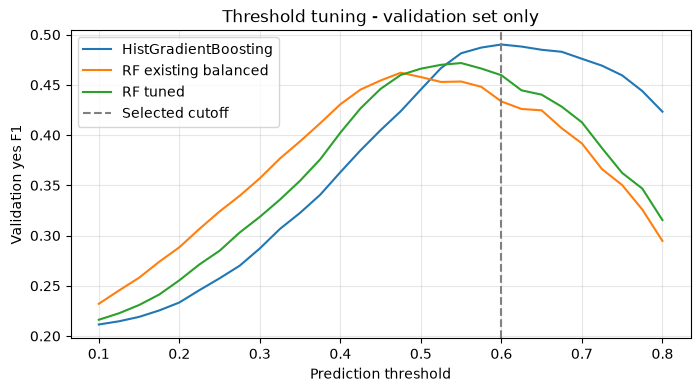

In [6]:
plt.figure(figsize=(8, 4))
for name, part in validation_results.groupby('model'):
    plt.plot(part['threshold'], part['f1'], label=name)
plt.axvline(best_threshold, color='gray', linestyle='--', label='Selected cutoff')
plt.xlabel('Prediction threshold')
plt.ylabel('Validation yes F1')
plt.title('Threshold tuning - validation set only')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 6. Train selected model on development data, evaluate once on test

After model/threshold selection, refit the selected structure on the 80% development set. The chosen cutoff comes from the smaller training/validation fit, so score distributions can move slightly after refitting. Report the held-out result as measured; do not retune based on it.

In [7]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

final_model = clone(candidates[best_name])
final_model.fit(X_dev, y_dev)

yes_idx = list(final_model.classes_).index('yes')
test_prob = final_model.predict_proba(X_test)[:, yes_idx]
test_pred = np.where(test_prob >= best_threshold, 'yes', 'no')

print('Final model:', best_name, '/ threshold:', best_threshold)
print('Test Accuracy:', round(accuracy_score(y_test, test_pred), 4))
print('Test yes F1:', round(f1_score(y_test, test_pred, pos_label='yes'), 4))
print('Test Average Precision:', round(
    average_precision_score((y_test == 'yes').astype(int), test_prob), 4
))
print('Confusion matrix (no, yes):')
print(confusion_matrix(y_test, test_pred, labels=['no', 'yes']))
print(classification_report(y_test, test_pred, labels=['no', 'yes'], zero_division=0))

Final model: HistGradientBoosting / threshold: 0.6
Test Accuracy: 0.8668
Test yes F1: 0.4975
Test Average Precision: 0.4573
Confusion matrix (no, yes):
[[7226  749]
 [ 453  595]]
              precision    recall  f1-score   support

          no       0.94      0.91      0.92      7975
         yes       0.44      0.57      0.50      1048

    accuracy                           0.87      9023
   macro avg       0.69      0.74      0.71      9023
weighted avg       0.88      0.87      0.87      9023



## 7. Prediction on optional submission CSV

No manual get_dummies or column reindexing is needed: the fitted Pipeline does it. This cell runs only if `input_bank_submission.csv` exists in your notebook working directory.

In [9]:
from pathlib import Path

submission_path = Path('input_bank_submission.csv')
if submission_path.exists():
    submission_raw = pd.read_csv(submission_path)
    missing = sorted(set(raw_X.columns) - set(submission_raw.columns))
    if missing:
        raise ValueError(f'Missing submission features: {missing}')

    submission_X = make_features(submission_raw[raw_X.columns])
    submission_prob = final_model.predict_proba(submission_X)[:, yes_idx]
    submission_pred = np.where(submission_prob >= best_threshold, 'yes', 'no')

    submission_result = pd.DataFrame({
        'y': submission_pred
        # 'yes_probability': submission_prob.round(4)
    })
    submission_result.to_csv('bank_predictions_optimized.csv', index=False)
    submission_result[['y']].to_csv('bank_predictions_y_only.csv', index=False)
    print('Saved bank_predictions_optimized.csv and bank_predictions_y_only.csv')
    display(submission_result.head())
else:
    print('No input_bank_submission.csv found; submission prediction skipped.')

Saved bank_predictions_optimized.csv and bank_predictions_y_only.csv


,y
0,yes
1,yes
2,yes
3,yes
4,yes


## Reading the result

- **F1 for yes** balances finding subscribers (recall) with avoiding wasted calls (precision).
- **Average precision / PR-AUC** assesses probability ranking for a rare positive class.
- If your business goal prioritizes maximum subscribers within a fixed call budget, consider precision at a fixed top-K instead of F1.
- A selected model can lose to the starting model on the held-out test set; tuning is an experiment, not a guarantee.
- For rigorous deployment evaluation, use new unseen data after all decisions are fixed.
